# Garbage Classification using ResNet50

This notebook trains a ResNet50 CNN model for garbage classification using transfer learning.

**Model:** ResNet50 (Pre-trained on ImageNet)  
**Input Size:** 224x224x3  
**Strategy:** Two-phase training (frozen base → fine-tuning)

## Step 1: Install Required Libraries

In [ ]:
!pip install roboflow tensorflow opencv-python matplotlib scikit-learn pillow seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 90.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 137.5 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


## Step 2: Download Dataset from Roboflow

In [ ]:
from roboflow import Roboflow
import os

# Initialize Roboflow with your API key
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("material-identification").project("garbage-classification-3")
version = project.version(1)

# Download dataset in a format suitable for classification (e.g., "tensorflow")
# Check if the dataset is already downloaded and if not, download it.
dataset_dir = "GARBAGE-CLASSIFICATION-3-1"  # Assuming this is the new dataset folder name
if not os.path.exists(dataset_dir):
    dataset = version.download("tensorflow")
    print(f"Dataset downloaded to: {dataset.location}")
else:
    print(f"Dataset already exists at: {dataset_dir}")
    dataset = type('obj', (object,), {'location': dataset_dir})() # Create a mock object with location attribute

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to GARBAGE-CLASSIFICATION-3-1 in tensorflow:: 100%|██████████| 17373/17373 [00:05<00:00, 3243.95it/s]

Dataset downloaded to: /content/GARBAGE-CLASSIFICATION-3-1


In [ ]:
import shutil
from pathlib import Path

def reorganize_dataset(base_dir):
    """
    Reorganize flat dataset structure into class subdirectories.
    Files are named like 'classname123_jpg.rf.hash.jpg'
    """
    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(base_dir, split)

        if not os.path.exists(split_dir):
            print(f"Directory not found: {split_dir}")
            continue

        # Get all image files (skip csv files)
        all_items = os.listdir(split_dir)
        files = [f for f in all_items if os.path.isfile(os.path.join(split_dir, f)) and f.endswith(('.jpg', '.jpeg', '.png'))]

        if not files:
            print(f"{split} - No images in root directory (already organized)")
            continue

        print(f"\nReorganizing {split} directory...")
        print(f"Found {len(files)} images to organize...")

        # Extract class names from filenames and create directories
        class_names = set()
        for filename in files:
            # Extract class name (everything before the first digit)
            class_name = ''.join([c for c in filename.split('_')[0] if not c.isdigit()])
            if class_name:
                class_names.add(class_name)

        print(f"Found classes: {sorted(class_names)}")

        # Create class directories
        for class_name in class_names:
            class_dir = os.path.join(split_dir, class_name)
            os.makedirs(class_dir, exist_ok=True)

        # Move files to appropriate class directories
        moved_count = 0
        for filename in files:
            # Extract class name
            class_name = ''.join([c for c in filename.split('_')[0] if not c.isdigit()])

            if class_name in class_names:
                src = os.path.join(split_dir, filename)
                dst = os.path.join(split_dir, class_name, filename)

                # Only move if source exists and destination doesn't
                if os.path.exists(src) and not os.path.exists(dst):
                    shutil.move(src, dst)
                    moved_count += 1

        print(f"Moved {moved_count} files into class subdirectories")

# Reorganize the dataset
dataset_path = dataset.location
print(f"Reorganizing dataset at: {dataset_path}")
reorganize_dataset(dataset_path)
print("\nDataset reorganization complete!")

Reorganizing dataset at: /content/GARBAGE-CLASSIFICATION-3-1

Reorganizing train directory...
Found 14225 images to organize...
Found classes: ['biodegradable', 'cardboard', 'glass', 'metal', 'paper', 'plastic']
Moved 14225 files into class subdirectories

Reorganizing valid directory...
Found 2098 images to organize...
Found classes: ['biodegradable', 'cardboard', 'glass', 'metal']
Moved 2098 files into class subdirectories

Reorganizing test directory...
Found 1042 images to organize...
Found classes: ['metal', 'paper', 'plastic']
Moved 1042 files into class subdirectories

Dataset reorganization complete!


In [ ]:
import random
import os
import shutil
from collections import defaultdict

def balance_dataset_splits(base_dir, train_ratio=0.7, valid_ratio=0.2, test_ratio=0.1, tolerance=0.05):
    """
    Collect all images from all splits and redistribute them with proper ratios.
    Ensures all classes appear in train, valid, and test splits.
    Only reorganizes if dataset is found to be unbalanced.
    """
    print("=" * 60)
    print("Checking dataset balance...")
    print("=" * 60)

    # Collect all images from all splits
    all_images = defaultdict(list)  # class_name -> list of image paths
    split_counts = defaultdict(lambda: defaultdict(int))  # split -> class -> count

    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(base_dir, split)
        if not os.path.exists(split_dir):
            continue

        # Look for class subdirectories
        for class_name in os.listdir(split_dir):
            class_path = os.path.join(split_dir, class_name)
            if not os.path.isdir(class_path):
                continue

            # Get all images in this class directory
            images = [f for f in os.listdir(class_path)
                     if f.endswith(('.jpg', '.jpeg', '.png'))]

            for img in images:
                img_path = os.path.join(class_path, img)
                all_images[class_name].append(img_path)
                split_counts[split][class_name] += 1

    if not all_images:
        print("No images found in class subdirectories!")
        return

    print(f"\nFound {len(all_images)} classes:")
    for class_name, imgs in all_images.items():
        print(f"  - {class_name}: {len(imgs)} images")

    # Check if dataset is balanced
    print("\nCurrent distribution:")
    print(f"{'Class':<15} {'Train':<10} {'Valid':<10} {'Test':<10} {'Total':<10}")
    print("-" * 60)

    needs_balancing = False
    missing_classes = []

    for class_name in sorted(all_images.keys()):
        train_count = split_counts['train'].get(class_name, 0)
        valid_count = split_counts['valid'].get(class_name, 0)
        test_count = split_counts['test'].get(class_name, 0)
        total_count = len(all_images[class_name])

        print(f"{class_name:<15} {train_count:<10} {valid_count:<10} {test_count:<10} {total_count:<10}")

        # Check if any split is missing this class
        if train_count == 0 or valid_count == 0 or test_count == 0:
            needs_balancing = True
            missing_classes.append(class_name)

        # Check if ratios are off
        actual_train_ratio = train_count / total_count if total_count > 0 else 0
        actual_valid_ratio = valid_count / total_count if total_count > 0 else 0
        actual_test_ratio = test_count / total_count if total_count > 0 else 0

        if (abs(actual_train_ratio - train_ratio) > tolerance or
            abs(actual_valid_ratio - valid_ratio) > tolerance or
            abs(actual_test_ratio - test_ratio) > tolerance):
            needs_balancing = True

    if not needs_balancing:
        print("\n✓ Dataset is already balanced! No reorganization needed.")
        return

    print("\n⚠ Dataset is UNBALANCED:")
    if missing_classes:
        print(f"  - Missing classes in some splits: {', '.join(missing_classes)}")
    print(f"  - Target ratios: Train={train_ratio:.0%}, Valid={valid_ratio:.0%}, Test={test_ratio:.0%}")
    print("\nProceeding with rebalancing...")

    # Shuffle and split for each class
    random.seed(42)  # For reproducibility
    train_files = defaultdict(list)
    valid_files = defaultdict(list)
    test_files = defaultdict(list)

    for class_name, image_paths in all_images.items():
        # Shuffle images
        shuffled = image_paths.copy()
        random.shuffle(shuffled)

        # Calculate split points
        total = len(shuffled)
        train_end = int(total * train_ratio)
        valid_end = train_end + int(total * valid_ratio)

        # Split
        train_files[class_name] = shuffled[:train_end]
        valid_files[class_name] = shuffled[train_end:valid_end]
        test_files[class_name] = shuffled[valid_end:]

    print("\n" + "=" * 60)
    print("New split distribution:")
    print("=" * 60)
    print(f"{'Class':<15} {'Train':<10} {'Valid':<10} {'Test':<10} {'Total':<10}")
    print("-" * 60)

    for class_name in sorted(all_images.keys()):
        train_count = len(train_files[class_name])
        valid_count = len(valid_files[class_name])
        test_count = len(test_files[class_name])
        total_count = train_count + valid_count + test_count
        print(f"{class_name:<15} {train_count:<10} {valid_count:<10} {test_count:<10} {total_count:<10}")

    # Now move files to their new locations
    print("\n" + "=" * 60)
    print("Reorganizing files...")
    print("=" * 60)

    # First, create new directories
    for split in ['train', 'valid', 'test']:
        for class_name in all_images.keys():
            new_dir = os.path.join(base_dir, split, class_name)
            os.makedirs(new_dir, exist_ok=True)

    # Move files
    move_count = 0
    for split_name, file_dict in [('train', train_files), ('valid', valid_files), ('test', test_files)]:
        for class_name, file_paths in file_dict.items():
            dest_dir = os.path.join(base_dir, split_name, class_name)
            for src_path in file_paths:
                filename = os.path.basename(src_path)
                dest_path = os.path.join(dest_dir, filename)

                # Only move if not already in the right place
                if src_path != dest_path:
                    # If destination exists, remove it first
                    if os.path.exists(dest_path):
                        os.remove(dest_path)
                    shutil.move(src_path, dest_path)
                    move_count += 1

    print(f"✓ Reorganized {move_count} files")

    # Clean up empty directories
    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(base_dir, split)
        if os.path.exists(split_dir):
            for class_name in os.listdir(split_dir):
                class_path = os.path.join(split_dir, class_name)
                if os.path.isdir(class_path):
                    try:
                        if not os.listdir(class_path):
                            os.rmdir(class_path)
                    except:
                        pass

    print("✓ Dataset balancing complete!\n")

# Balance the dataset
balance_dataset_splits(dataset_path)


Checking dataset balance...

Found 6 classes:
  - paper: 2891 images
  - biodegradable: 3692 images
  - plastic: 1928 images
  - metal: 2074 images
  - cardboard: 2379 images
  - glass: 4401 images

Current distribution:
Class           Train      Valid      Test       Total     
------------------------------------------------------------
biodegradable   3026       666        0          3692      
cardboard       1946       433        0          2379      
glass           3606       795        0          4401      
metal           1700       204        170        2074      
paper           2368       0          523        2891      
plastic         1579       0          349        1928      

⚠ Dataset is UNBALANCED:
  - Missing classes in some splits: biodegradable, cardboard, glass, paper, plastic
  - Target ratios: Train=70%, Valid=20%, Test=10%

Proceeding with rebalancing...

New split distribution:
Class           Train      Valid      Test       Total     
---------------------

## Step 2.6: Balance Dataset with 70-20-10 Split

Redistribute all images across train/valid/test splits to ensure all classes are present in all splits.

## Step 2.5: Reorganize Dataset Structure

The Roboflow dataset has a flat structure with class prefixes in filenames. We need to reorganize it into subdirectories for each class.

## Step 3: Import Required Libraries

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 4: Prepare Data Generators

ResNet50 requires images to be 224x224 pixels. We'll use data augmentation to improve model generalization.

In [ ]:
# Set dataset paths
dataset_path = dataset.location
train_dir = os.path.join(dataset_path, 'train')
val_dir = os.path.join(dataset_path, 'valid')
test_dir = os.path.join(dataset_path, 'test')

print(f"Dataset path: {dataset_path}")
print(f"Train directory: {train_dir}")
print(f"Validation directory: {val_dir}")
print(f"Test directory: {test_dir}")

# Image parameters
IMG_SIZE = 224
BATCH_SIZE = 32

# Data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only rescaling for validation and test
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Get class information
num_classes = len(train_generator.class_indices)
class_names = list(train_generator.class_indices.keys())

print(f"\nNumber of classes: {num_classes}")
print(f"Class names: {class_names}")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Test samples: {test_generator.samples}")

Dataset path: /content/GARBAGE-CLASSIFICATION-3-1
Train directory: /content/GARBAGE-CLASSIFICATION-3-1/train
Validation directory: /content/GARBAGE-CLASSIFICATION-3-1/valid
Test directory: /content/GARBAGE-CLASSIFICATION-3-1/test
Found 12152 images belonging to 6 classes.
Found 3470 images belonging to 6 classes.
Found 1743 images belonging to 6 classes.

Number of classes: 6
Class names: ['biodegradable', 'cardboard', 'glass', 'metal', 'paper', 'plastic']
Training samples: 12152
Validation samples: 3470
Test samples: 1743


## Step 5: Visualize Sample Images

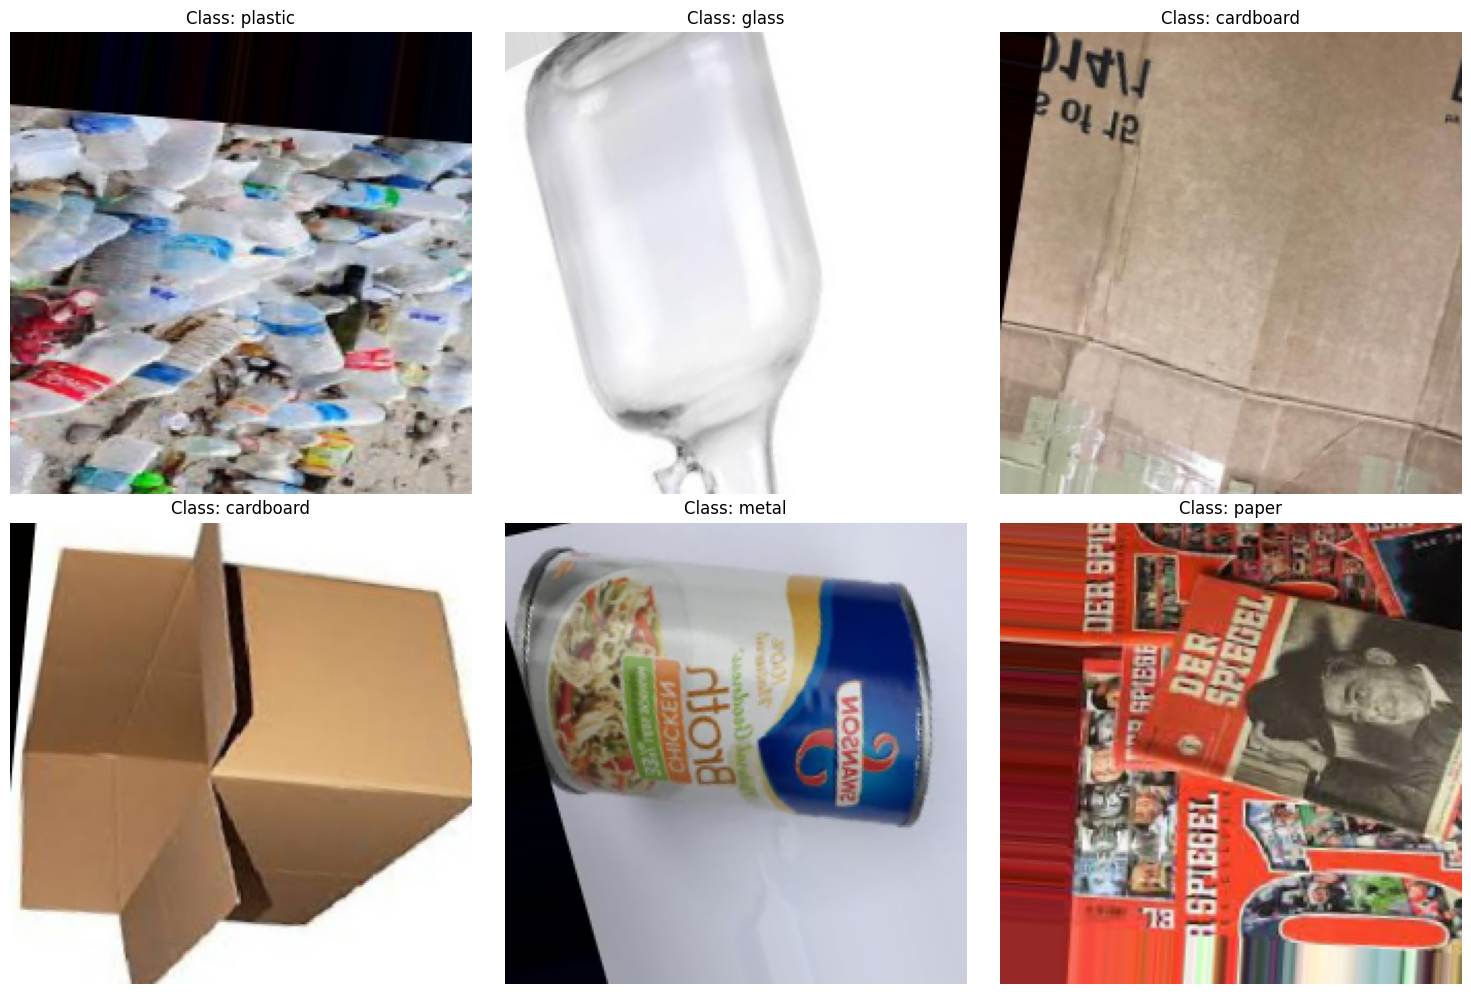

In [ ]:
# Display sample images with their labels
sample_batch, sample_labels = next(train_generator)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx in range(6):
    axes[idx].imshow(sample_batch[idx])
    class_idx = np.argmax(sample_labels[idx])
    axes[idx].set_title(f'Class: {class_names[class_idx]}', fontsize=12)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## Step 6: Build ResNet50 Model with Transfer Learning

We'll use a pre-trained ResNet50 (trained on ImageNet) and fine-tune it for garbage classification.

In [ ]:
# Load pre-trained ResNet50 without top layers
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze base model layers initially
base_model.trainable = False

# Build custom classification head
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')]
)

print("\nModel Architecture:")
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step

Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,777,862 (94.52 MB)

 Trainable params: 1,186,054 (4.52 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

## Step 7: Train the Model (Phase 1 - Frozen Base)

First, train only the custom layers while keeping ResNet50 frozen.

In [ ]:
# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7
    ),
    keras.callbacks.ModelCheckpoint(
        'resnet50_garbage_phase1.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Train model - Phase 1
print("\nPhase 1: Training with frozen base model...")
history_phase1 = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("Phase 1 training completed!")


Phase 1: Training with frozen base model...


Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.3260 - loss: 1.7475 - top3_accuracy: 0.6696
Epoch 1: val_accuracy improved from -inf to 0.41066, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 227s 548ms/step - accuracy: 0.3261 - loss: 1.7473 - top3_accuracy: 0.6696 - val_accuracy: 0.4107 - val_loss: 1.5857 - val_top3_accuracy: 0.7703 - learning_rate: 0.0010
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.4006 - loss: 1.5418 - top3_accuracy: 0.7306
Epoch 2: val_accuracy improved from 0.41066 to 0.45043, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 188s 494ms/step - accuracy: 0.4006 - loss: 1.5418 - top3_accuracy: 0.7306 - val_accuracy: 0.4504 - val_loss: 1.4421 - val_top3_accuracy: 0.7821 - learning_rate: 0.0010
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.4064 - loss: 1.5145 - top3_accuracy: 0.7483
Epoch 3: val_accuracy improved from 0.45043 to 0.46311, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 190s 500ms/step - accuracy: 0.4064 - loss: 1.5145 - top3_accuracy: 0.7483 - val_accuracy: 0.4631 - val_loss: 1.3663 - val_top3_accuracy: 0.8110 - learning_rate: 0.0010
Epoch 4/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.4223 - loss: 1.4829 - top3_accuracy: 0.7635
Epoch 4: val_accuracy did not improve from 0.46311
380/380 ━━━━━━━━━━━━━━━━━━━━ 189s 498ms/step - accuracy: 0.4223 - loss: 1.4829 - top3_accuracy: 0.7635 - val_accuracy: 0.4591 - val_loss: 1.3499 - val_top3_accuracy: 0.8133 - learning_rate: 0.0010
Epoch 5/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.4429 - loss: 1.4578 - top3_accuracy: 0.7695
Epoch 5: val_accuracy improved from 0.46311 to 0.48386, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 191s 502ms/step - accuracy: 0.4429 - loss: 1.4578 - top3_accuracy: 0.7695 - val_accuracy: 0.4839 - val_loss: 1.3462 - val_top3_accuracy: 0.8213 - learning_rate: 0.0010
Epoch 6/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.4423 - loss: 1.4346 - top3_accuracy: 0.7827
Epoch 6: val_accuracy improved from 0.48386 to 0.49971, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 192s 506ms/step - accuracy: 0.4423 - loss: 1.4346 - top3_accuracy: 0.7827 - val_accuracy: 0.4997 - val_loss: 1.2955 - val_top3_accuracy: 0.8409 - learning_rate: 0.0010
Epoch 7/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.4405 - loss: 1.4452 - top3_accuracy: 0.7787
Epoch 7: val_accuracy did not improve from 0.49971
380/380 ━━━━━━━━━━━━━━━━━━━━ 193s 507ms/step - accuracy: 0.4405 - loss: 1.4452 - top3_accuracy: 0.7787 - val_accuracy: 0.4896 - val_loss: 1.3024 - val_top3_accuracy: 0.8392 - learning_rate: 0.0010
Epoch 8/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.4522 - loss: 1.4188 - top3_accuracy: 0.7890
Epoch 8: val_accuracy improved from 0.49971 to 0.50375, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 191s 502ms/step - accuracy: 0.4522 - loss: 1.4188 - top3_accuracy: 0.7890 - val_accuracy: 0.5037 - val_loss: 1.2912 - val_top3_accuracy: 0.8429 - learning_rate: 0.0010
Epoch 9/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.4658 - loss: 1.4026 - top3_accuracy: 0.7988
Epoch 9: val_accuracy improved from 0.50375 to 0.53718, saving model to resnet50_garbage_phase1.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 190s 499ms/step - accuracy: 0.4658 - loss: 1.4026 - top3_accuracy: 0.7988 - val_accuracy: 0.5372 - val_loss: 1.2389 - val_top3_accuracy: 0.8496 - learning_rate: 0.0010
Epoch 10/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.4682 - loss: 1.3954 - top3_accuracy: 0.8024
Epoch 10: val_accuracy did not improve from 0.53718
380/380 ━━━━━━━━━━━━━━━━━━━━ 189s 497ms/step - accuracy: 0.4682 - loss: 1.3954 - top3_accuracy: 0.8024 - val_accuracy: 0.4997 - val_loss: 1.2912 - val_top3_accuracy: 0.8386 - learning_rate: 0.0010
Phase 1 training completed!


## Step 8: Fine-tune the Model (Phase 2 - Unfrozen Base)

Unfreeze the last few layers of ResNet50 for fine-tuning.

In [ ]:
# Unfreeze the base model
base_model.trainable = True

# Freeze all layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

print(f"Number of trainable layers: {len([l for l in model.layers if l.trainable])}")

# Recompile with lower learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')]
)

# Update callbacks
callbacks[2] = keras.callbacks.ModelCheckpoint(
    'resnet50_garbage_best.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train model - Phase 2
print("\nPhase 2: Fine-tuning unfrozen layers...")
history_phase2 = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("Phase 2 training completed!")

Number of trainable layers: 8

Phase 2: Fine-tuning unfrozen layers...
Epoch 1/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.3557 - loss: 1.7143 - top3_accuracy: 0.6959
Epoch 1: val_accuracy improved from -inf to 0.41210, saving model to resnet50_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 230s 546ms/step - accuracy: 0.3558 - loss: 1.7140 - top3_accuracy: 0.6960 - val_accuracy: 0.4121 - val_loss: 1.5645 - val_top3_accuracy: 0.7124 - learning_rate: 1.0000e-05
Epoch 2/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.4204 - loss: 1.5144 - top3_accuracy: 0.7618
Epoch 2: val_accuracy improved from 0.41210 to 0.48184, saving model to resnet50_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 192s 505ms/step - accuracy: 0.4204 - loss: 1.5143 - top3_accuracy: 0.7618 - val_accuracy: 0.4818 - val_loss: 1.3516 - val_top3_accuracy: 0.8268 - learning_rate: 1.0000e-05
Epoch 3/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.4472 - loss: 1.4495 - top3_accuracy: 0.7792
Epoch 3: val_accuracy improved from 0.48184 to 0.48646, saving model to resnet50_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 193s 507ms/step - accuracy: 0.4472 - loss: 1.4495 - top3_accuracy: 0.7792 - val_accuracy: 0.4865 - val_loss: 1.3658 - val_top3_accuracy: 0.7942 - learning_rate: 1.0000e-05
Epoch 4/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.4421 - loss: 1.4501 - top3_accuracy: 0.7724
Epoch 4: val_accuracy did not improve from 0.48646
380/380 ━━━━━━━━━━━━━━━━━━━━ 191s 502ms/step - accuracy: 0.4421 - loss: 1.4500 - top3_accuracy: 0.7725 - val_accuracy: 0.4464 - val_loss: 1.3704 - val_top3_accuracy: 0.8231 - learning_rate: 1.0000e-05
Epoch 5/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.4609 - loss: 1.4119 - top3_accuracy: 0.7901
Epoch 5: val_accuracy improved from 0.48646 to 0.49625, saving model to resnet50_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 194s 510ms/step - accuracy: 0.4609 - loss: 1.4118 - top3_accuracy: 0.7901 - val_accuracy: 0.4963 - val_loss: 1.3183 - val_top3_accuracy: 0.8251 - learning_rate: 1.0000e-05
Epoch 6/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.4740 - loss: 1.3897 - top3_accuracy: 0.7973
Epoch 6: val_accuracy did not improve from 0.49625
380/380 ━━━━━━━━━━━━━━━━━━━━ 193s 508ms/step - accuracy: 0.4740 - loss: 1.3897 - top3_accuracy: 0.7973 - val_accuracy: 0.4925 - val_loss: 1.3103 - val_top3_accuracy: 0.8265 - learning_rate: 1.0000e-05
Epoch 7/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.4763 - loss: 1.3767 - top3_accuracy: 0.8103
Epoch 7: val_accuracy improved from 0.49625 to 0.52017, saving model to resnet50_garbage_best.h5


380/380 ━━━━━━━━━━━━━━━━━━━━ 192s 505ms/step - accuracy: 0.4763 - loss: 1.3767 - top3_accuracy: 0.8102 - val_accuracy: 0.5202 - val_loss: 1.2675 - val_top3_accuracy: 0.8401 - learning_rate: 1.0000e-05
Epoch 8/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step - accuracy: 0.4818 - loss: 1.3662 - top3_accuracy: 0.8088
Epoch 8: val_accuracy did not improve from 0.52017
380/380 ━━━━━━━━━━━━━━━━━━━━ 193s 508ms/step - accuracy: 0.4818 - loss: 1.3662 - top3_accuracy: 0.8088 - val_accuracy: 0.5187 - val_loss: 1.2676 - val_top3_accuracy: 0.8507 - learning_rate: 1.0000e-05
Epoch 9/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.4757 - loss: 1.3470 - top3_accuracy: 0.8120
Epoch 9: val_accuracy did not improve from 0.52017
380/380 ━━━━━━━━━━━━━━━━━━━━ 193s 508ms/step - accuracy: 0.4757 - loss: 1.3470 - top3_accuracy: 0.8120 - val_accuracy: 0.5161 - val_loss: 1.2629 - val_top3_accuracy: 0.8450 - learning_rate: 1.0000e-05
Epoch 10/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.48

380/380 ━━━━━━━━━━━━━━━━━━━━ 189s 497ms/step - accuracy: 0.4850 - loss: 1.3488 - top3_accuracy: 0.8147 - val_accuracy: 0.5207 - val_loss: 1.2566 - val_top3_accuracy: 0.8389 - learning_rate: 1.0000e-05
Epoch 11/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.5035 - loss: 1.3348 - top3_accuracy: 0.8231
Epoch 11: val_accuracy did not improve from 0.52075
380/380 ━━━━━━━━━━━━━━━━━━━━ 187s 493ms/step - accuracy: 0.5035 - loss: 1.3348 - top3_accuracy: 0.8231 - val_accuracy: 0.5153 - val_loss: 1.2972 - val_top3_accuracy: 0.8239 - learning_rate: 1.0000e-05
Epoch 12/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.4960 - loss: 1.3121 - top3_accuracy: 0.8242
Epoch 12: val_accuracy did not improve from 0.52075
380/380 ━━━━━━━━━━━━━━━━━━━━ 192s 506ms/step - accuracy: 0.4960 - loss: 1.3121 - top3_accuracy: 0.8242 - val_accuracy: 0.4960 - val_loss: 1.2976 - val_top3_accuracy: 0.8294 - learning_rate: 1.0000e-05
Epoch 13/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 

380/380 ━━━━━━━━━━━━━━━━━━━━ 191s 501ms/step - accuracy: 0.5150 - loss: 1.2904 - top3_accuracy: 0.8292 - val_accuracy: 0.5553 - val_loss: 1.1984 - val_top3_accuracy: 0.8585 - learning_rate: 5.0000e-06
Epoch 15/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 0s 472ms/step - accuracy: 0.5201 - loss: 1.2703 - top3_accuracy: 0.8381
Epoch 15: val_accuracy did not improve from 0.55533
380/380 ━━━━━━━━━━━━━━━━━━━━ 189s 497ms/step - accuracy: 0.5201 - loss: 1.2703 - top3_accuracy: 0.8381 - val_accuracy: 0.5170 - val_loss: 1.3087 - val_top3_accuracy: 0.8476 - learning_rate: 5.0000e-06
Phase 2 training completed!


## Step 9: Visualize Training History

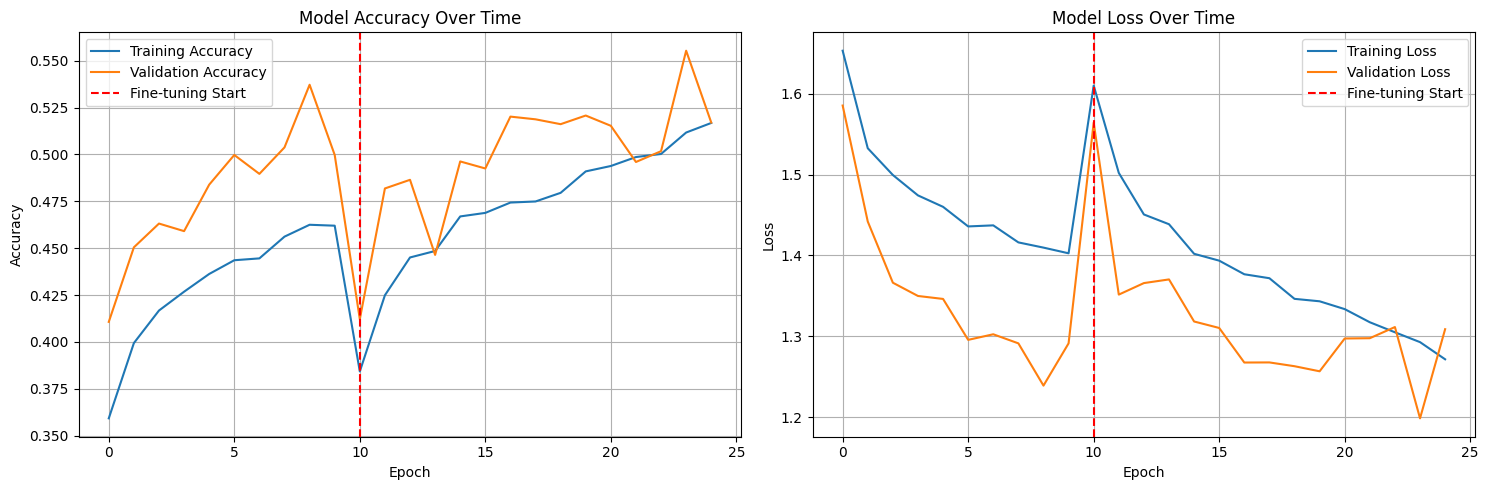

In [ ]:
# Combine histories
history_combined = {
    'accuracy': history_phase1.history['accuracy'] + history_phase2.history['accuracy'],
    'val_accuracy': history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy'],
    'loss': history_phase1.history['loss'] + history_phase2.history['loss'],
    'val_loss': history_phase1.history['val_loss'] + history_phase2.history['val_loss']
}

# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
ax1.plot(history_combined['accuracy'], label='Training Accuracy')
ax1.plot(history_combined['val_accuracy'], label='Validation Accuracy')
ax1.axvline(x=len(history_phase1.history['accuracy']), color='r', linestyle='--', label='Fine-tuning Start')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy Over Time')
ax1.legend()
ax1.grid(True)

# Loss plot
ax2.plot(history_combined['loss'], label='Training Loss')
ax2.plot(history_combined['val_loss'], label='Validation Loss')
ax2.axvline(x=len(history_phase1.history['loss']), color='r', linestyle='--', label='Fine-tuning Start')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Model Loss Over Time')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

## Step 10: Evaluate Model Performance

In [ ]:
# Evaluate on validation set
print("Evaluating model on validation set...")
val_loss, val_accuracy, val_top3_accuracy = model.evaluate(val_generator)

print(f"\nValidation Metrics:")
print(f"Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
print(f"Top-3 Accuracy: {val_top3_accuracy:.4f} ({val_top3_accuracy*100:.2f}%)")

# Evaluate on test set
print("\nEvaluating model on test set...")
test_loss, test_accuracy, test_top3_accuracy = model.evaluate(test_generator)

print(f"\nTest Metrics:")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Top-3 Accuracy: {test_top3_accuracy:.4f} ({test_top3_accuracy*100:.2f}%)")

Evaluating model on validation set...
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 91ms/step - accuracy: 0.5482 - loss: 1.2230 - top3_accuracy: 0.8553

Validation Metrics:
Loss: 1.1984
Accuracy: 0.5553 (55.53%)
Top-3 Accuracy: 0.8585 (85.85%)

Evaluating model on test set...
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 169ms/step - accuracy: 0.6155 - loss: 1.1481 - top3_accuracy: 0.8809

Test Metrics:
Loss: 1.2113
Accuracy: 0.5536 (55.36%)
Top-3 Accuracy: 0.8589 (85.89%)


## Step 11: Generate Confusion Matrix

In [ ]:
# Get predictions
test_generator.reset()
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - ResNet50', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

## Step 12: Test Model on Sample Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


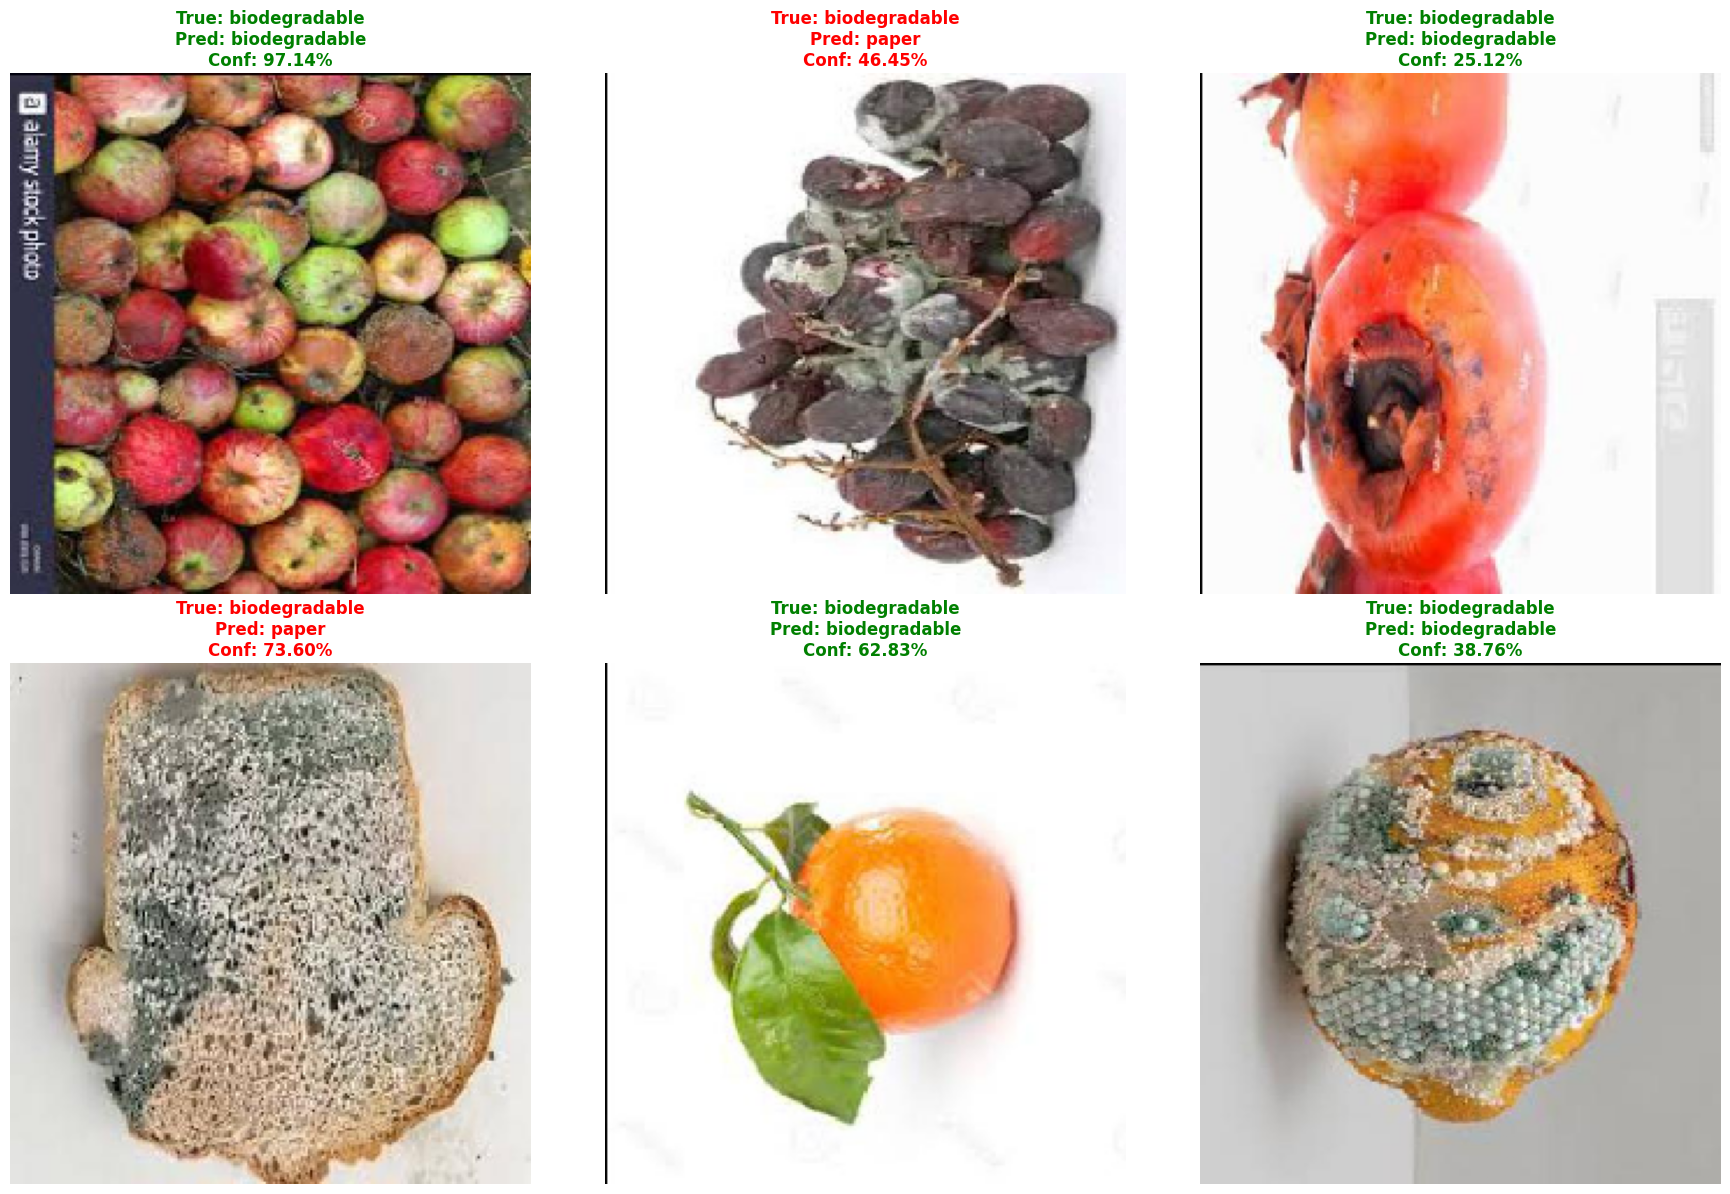

In [ ]:
# Get sample predictions
test_generator.reset()
sample_batch, sample_labels = next(test_generator)
predictions = model.predict(sample_batch)

# Display predictions
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for idx in range(6):
    axes[idx].imshow(sample_batch[idx])

    true_class_idx = np.argmax(sample_labels[idx])
    pred_class_idx = np.argmax(predictions[idx])
    confidence = predictions[idx][pred_class_idx]

    true_label = class_names[true_class_idx]
    pred_label = class_names[pred_class_idx]

    color = 'green' if true_class_idx == pred_class_idx else 'red'
    axes[idx].set_title(
        f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.2%}',
        color=color,
        fontweight='bold'
    )
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## Step 13: Save Model

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define the directory in your Drive to save the models
# Make sure this directory exists in your Google Drive
save_dir = '/content/drive/MyDrive/GarbageClassificationModels'
os.makedirs(save_dir, exist_ok=True)

# Save weights only
model.save(os.path.join(save_dir, 'resnet50_garbage_weights.h5'))
print(f"Model weights saved to '{os.path.join(save_dir, 'resnet50_garbage_weights.h5')}'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model weights saved to '/content/drive/MyDrive/GarbageClassificationModels/resnet50_garbage_weights.h5'


## Model Summary

**Architecture:** ResNet50 with custom classification head  
**Transfer Learning:** Pre-trained on ImageNet  
**Training Strategy:** Two-phase (frozen base → fine-tuning)  
**Input Size:** 224x224x3  
**Parameters:** ~25M total (23.5M from ResNet50 base)  
**Optimizer:** Adam with learning rate scheduling  
**Data Augmentation:** Rotation, shift, shear, zoom, flip  